# 17 — Thiết kế proxy label

> **Phạm vi:** proof of concept phân loại motion phenotype dựa trên proxy label — KHÔNG phải bộ phân loại an toàn hàng hải đã xác thực. Proxy label không phải ground truth; không có nhãn hazard đã xác minh hay quyết định human review nào được dùng.

Notebook trình bày lý do, phương trình, nghiên cứu hiệu chuẩn, độ nhạy và ví dụ ABSTAIN của `proxy_rules_v1.0.0`.
Đặc tả: `ml/labeling/proxy_spec.yaml`; báo cáo: `ml/reports/ml/proxy_label_specification.md`.

| Khái niệm | Ý nghĩa |
|---|---|
| Observed motion phenotype | Hình thái tín hiệu quan sát được |
| Proxy rule label | Nhãn tự động theo quy tắc tái lập (dùng ở đây) |
| Human-reviewed observation | Người xác nhận (hiện 0) |
| Verified operational hazard | Nguồn độc lập xác nhận nguy hiểm (hiện 0) |

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "ml/labeling/proxy_rules.py").is_file():
    REPO_ROOT = next(p for p in Path.cwd().parents if (p / "ml/labeling/proxy_rules.py").is_file())
sys.path.insert(0, str(REPO_ROOT))
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.unicode_minus": False, "figure.dpi": 100, "font.size": 9})
PROXY = REPO_ROOT / "ml/data/labels/proxy_v1"
summary = json.loads((REPO_ROOT / "ml/reports/ml/proxy_dataset_summary.json").read_text())
measurements = pd.read_parquet(PROXY / "measurements.parquet")
labels = pd.read_parquet(PROXY / "proxy_labels_oof.parquet")
data = measurements.merge(labels, on="window_id", validate="one_to_one")
TARGETS = ["RELATIVE_HIGH_ROLL", "PERSISTENT_OFFSET", "AMPLITUDE_GROWTH"]
import sklearn
exe = Path(sys.executable)
print("Interpreter:", exe.relative_to(REPO_ROOT) if REPO_ROOT in exe.parents else exe.name, "| scikit-learn", sklearn.__version__)
print("Rule version:", summary["rule_version"], "| cửa sổ:", len(data), "| đủ 23 feature:", int(data.angle23_complete.sum()))

Interpreter: .venv/bin/python | scikit-learn 1.9.1
Rule version: proxy_rules_v1.0.0 | cửa sổ: 3425 | đủ 23 feature: 2864


## Phương trình

- **RELATIVE_HIGH_ROLL:** $s_{60}=\sqrt{\frac1n\sum (x_i-\bar x)^2}$ trên $(t-60,t]$; POS nếu $s_{60}\ge Q_{0.90}^{train}$, NEG nếu $s_{60}<Q_{0.80}^{train}$, còn lại ABSTAIN.
- **PERSISTENT_OFFSET (so với mốc 0 cảm biến):** POS nếu mọi mẫu cửa sổ và bối cảnh cùng dấu và 9/9 mean sub-block 20 s cùng dấu; NEG nếu mean sub-block đổi dấu; còn lại ABSTAIN. Không phải heel vật lý.
- **AMPLITUDE_GROWTH:** $g=\ln(\sigma_{late60}/\sigma_{early60})$ với σ quanh mean; POS nếu $g\ge Q_{0.95}^{train}$ **và** σ ba block tăng đơn điệu **và** σ block cuối vượt mọi σ 20 s của bối cảnh; NEG nếu $g<Q_{0.90}^{train}$.

Phân vị có trọng số đều theo session, chỉ fit trên nhóm train (điều kiện T của Hohai).

In [2]:
import yaml
spec = yaml.safe_load((REPO_ROOT / "ml/labeling/proxy_spec.yaml").read_text())
print(yaml.safe_dump(spec["rules"], allow_unicode=True, sort_keys=False))

RELATIVE_HIGH_ROLL:
  statistic: roll_std_60
  positive_quantile: 0.9
  negative_quantile: 0.8
PERSISTENT_OFFSET:
  reference: SENSOR_DATUM_UNVERIFIED
  require_context_same_sign: true
  calibration: none
AMPLITUDE_GROWTH:
  statistic: log_centered_std_ratio
  positive_quantile: 0.95
  negative_quantile: 0.9
  require_monotonic_blocks: true
  require_exceeds_context_max: true
  minimum_context_fraction: 0.95



## Nghiên cứu hiệu chuẩn: phân phối thống kê và ngưỡng của 9 outer fold (Hohai)

Vùng tô là khoảng min–max của ngưỡng qua 9 fold; mỗi fold fit trên 8 điều kiện T khác.

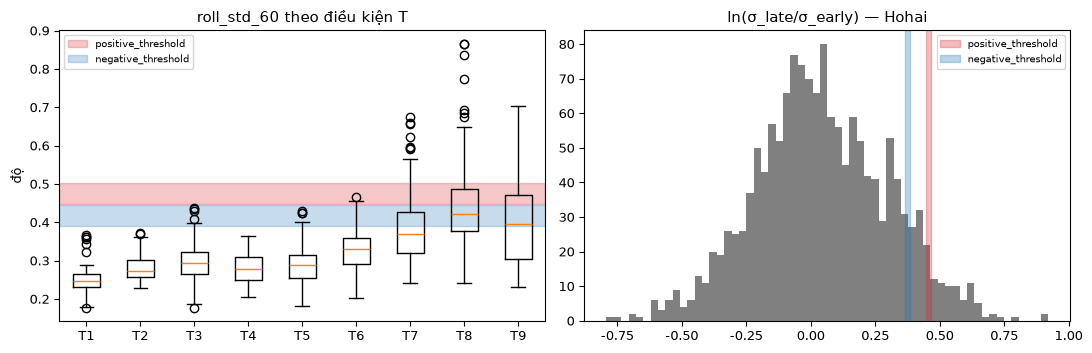

,RELATIVE_HIGH_ROLL,AMPLITUDE_GROWTH
positive_threshold,0.4478–0.5028,0.4485–0.4663
negative_threshold,0.3896–0.4456,0.3637–0.3840


In [3]:
h = data[(data.dataset_source == "hohai") & data.angle23_complete]
st = summary["threshold_stability"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
groups = sorted(h.experiment_group.unique())
axes[0].boxplot([h.loc[h.experiment_group == g, "roll_std_60"] for g in groups], tick_labels=[g.split("|")[1] for g in groups])
for key, color in (("positive_threshold", "tab:red"), ("negative_threshold", "tab:blue")):
    axes[0].axhspan(st["RELATIVE_HIGH_ROLL"][key]["min"], st["RELATIVE_HIGH_ROLL"][key]["max"], color=color, alpha=.25, label=key)
axes[0].set_title("roll_std_60 theo điều kiện T"); axes[0].set_ylabel("độ"); axes[0].legend(fontsize=7)
axes[1].hist(h.log_centered_std_ratio, bins=60, color="gray")
for key, color in (("positive_threshold", "tab:red"), ("negative_threshold", "tab:blue")):
    axes[1].axvspan(st["AMPLITUDE_GROWTH"][key]["min"], st["AMPLITUDE_GROWTH"][key]["max"], color=color, alpha=.3, label=key)
axes[1].set_title("ln(σ_late/σ_early) — Hohai"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
display(pd.DataFrame({t: {k: f"{v['min']:.4f}–{v['max']:.4f}" for k, v in s.items()} for t, s in st.items()}))

Toàn bộ cửa sổ POS của `RELATIVE_HIGH_ROLL` nằm ở T7–T9: proxy tương đối này thực chất phân biệt mức kích thích sóng của thí nghiệm.

## Độ nhạy theo lựa chọn phân vị

Mỗi biến thể lặp lại toàn bộ quy trình out-of-fold. Jaccard so tập POS với cấu hình mặc định.

,target,positive_quantile,negative_quantile,positive,negative,abstain,positive_groups,positive_sessions,jaccard_vs_default_positive_set
0,RELATIVE_HIGH_ROLL,0.800,0.70,394,989,381,4,10,0.530457
1,RELATIVE_HIGH_ROLL,0.850,0.75,308,1039,417,3,9,0.678571
2,RELATIVE_HIGH_ROLL,0.900,0.80,209,1118,437,3,9,1.000000
3,RELATIVE_HIGH_ROLL,0.950,0.90,112,1303,349,3,8,0.535885
4,AMPLITUDE_GROWTH,0.900,0.80,11,1206,547,4,4,0.727273
5,AMPLITUDE_GROWTH,0.950,0.90,8,1360,396,3,3,1.000000
6,AMPLITUDE_GROWTH,0.975,0.95,3,1433,328,2,2,0.375000


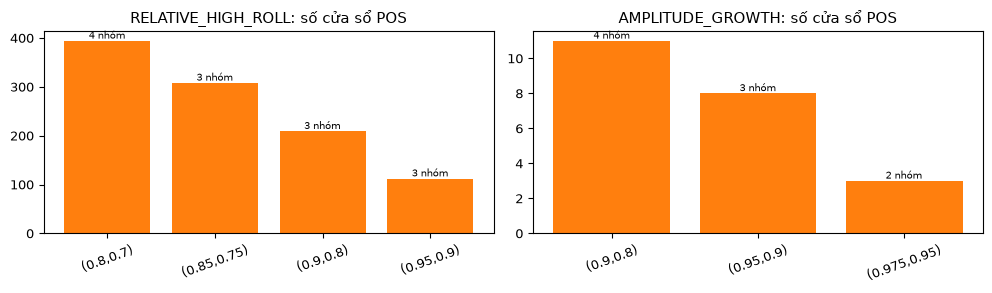

In [4]:
rows = [dict(target=t, **r) for t, rs in summary["sensitivity"].items() for r in rs]
sens = pd.DataFrame(rows); display(sens)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for i, t in enumerate(summary["sensitivity"]):
    s = sens[sens.target == t]
    ax[i].bar([f"({a},{b})" for a, b in zip(s.positive_quantile, s.negative_quantile)], s.positive, color="tab:orange")
    for x, (p, g) in enumerate(zip(s.positive, s.positive_groups)):
        ax[i].text(x, p, f"{g} nhóm", ha="center", va="bottom", fontsize=7)
    ax[i].set_title(f"{t}: số cửa sổ POS"); ax[i].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## RMS thô che tăng biên độ khi có offset

So sánh tỷ lệ RMS thô (feature `roll_rms_ratio_180`) với tỷ lệ σ quanh mean trên mọi cửa sổ hợp lệ.

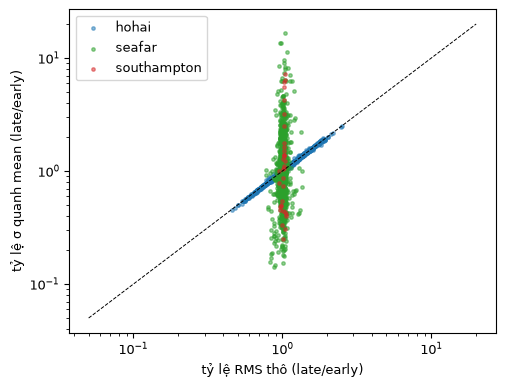

,sub_std_lag1_median,half_cycle_amplitude_lag1_median,half_cycle_amplitude_lag1_share_above_0_5,median_offset_to_oscillation_ratio,max_abs_centered_minus_raw_ratio,windows_where_centered_ratio_exceeds_raw_by_1_5x
hohai,-0.071803,0.758300,0.947090,0.079674,0.104649,0.0
seafar,0.169186,-0.090019,0.017081,27.584777,15.537217,291.0
southampton,0.015677,-0.106357,0.205882,27.720881,6.199421,9.0


In [5]:
v = data[data.angle23_complete & data.statistics_valid]
fig, ax = plt.subplots(figsize=(5.5, 4.2))
for ds, c in (("hohai", "tab:blue"), ("seafar", "tab:green"), ("southampton", "tab:red")):
    s = v[v.dataset_source == ds]; ax.scatter(s.raw_rms_ratio, s.centered_std_ratio, s=6, alpha=.5, c=c, label=ds)
ax.set_xscale("log"); ax.set_yscale("log"); lim = [0.05, 20]; ax.plot(lim, lim, "k--", lw=.7)
ax.set_xlabel("tỷ lệ RMS thô (late/early)"); ax.set_ylabel("tỷ lệ σ quanh mean (late/early)"); ax.legend(); plt.show()
display(pd.DataFrame(summary["assumption_checks"]).T)

Seafar/Southampton có |mean|/std rất lớn nên RMS thô ≈ |mean| và gần như không đổi, dù σ dao động thay đổi nhiều lần. Đây là lý do proxy growth dùng σ quanh mean. Tự tương quan lag-1 cao của biên độ nửa chu kỳ ở Hohai cho thấy giả định độc lập của Mann–Kendall bị vi phạm, nên p-value không được dùng để quyết định.

## Kiểm tra tính nhân quả trên một segment thật

Thay toàn bộ mẫu **sau** endpoint bằng giá trị 50° và tính lại: thống kê phải không đổi.

In [6]:
from ml.labeling.proxy_rules import load_spec, window_statistics
spec_obj = load_spec(REPO_ROOT / "ml/labeling/proxy_spec.yaml")
row = h.iloc[40]
ts = pd.read_parquet(REPO_ROOT / row.processed_path)
t, x = ts.time_seconds.to_numpy(), ts.roll_deg.to_numpy(float)
base = window_statistics(t, x, row.window_end_seconds, t[0], t[-1], spec_obj)
x2 = x.copy(); x2[t > row.window_end_seconds] = 50.0
changed = window_statistics(t, x2, row.window_end_seconds, t[0], t[-1], spec_obj)
diff = [k for k in base if k not in ("seconds_after_endpoint_in_segment", "near_segment_end_audit") and base[k] != changed[k] and not (isinstance(base[k], float) and np.isnan(base[k]))]
print(row.window_id, "| khác biệt sau khi sửa tương lai:", diff or "không có")

hohai|Berth_B_T7_Type_A|segment_000|582.000000 | khác biệt sau khi sửa tương lai: không có


## Ví dụ ABSTAIN thực tế

Mỗi hình là một cửa sổ thật (vùng xanh) cùng bối cảnh 180 s trước đó; không có dữ liệu sau endpoint.

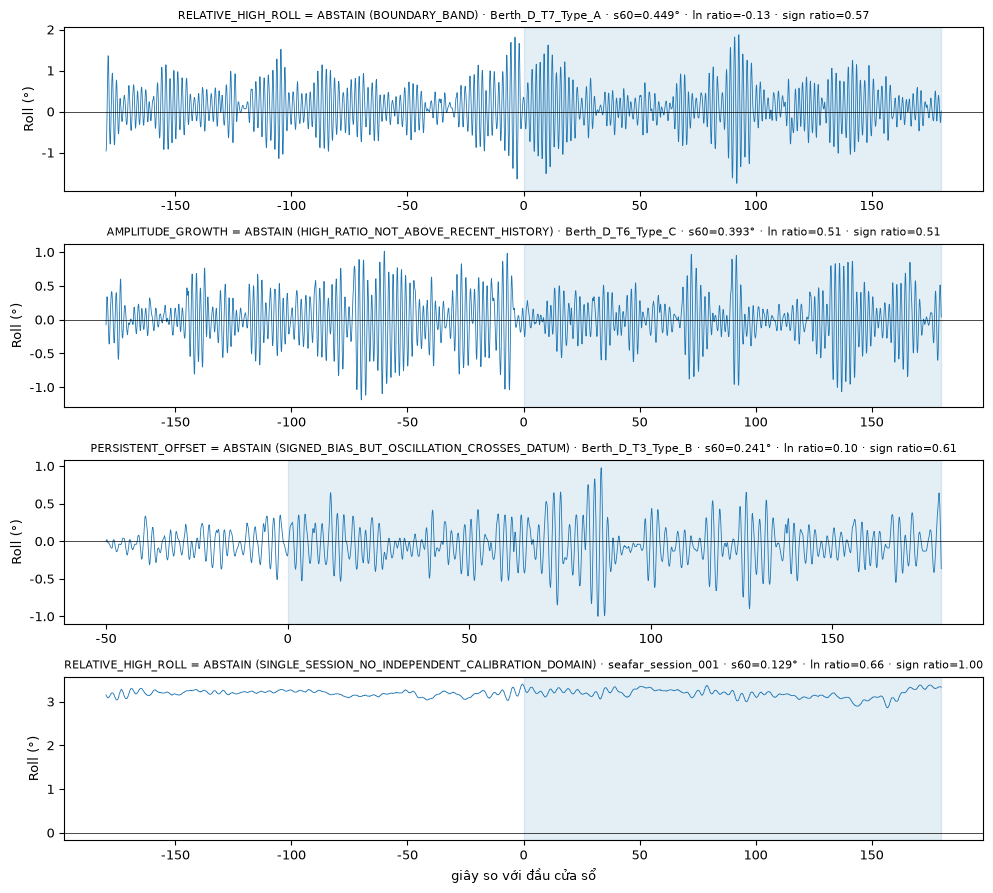

In [7]:
examples = [("RELATIVE_HIGH_ROLL", "BOUNDARY_BAND"), ("AMPLITUDE_GROWTH", "HIGH_RATIO_NOT_ABOVE_RECENT_HISTORY"),
            ("PERSISTENT_OFFSET", "SIGNED_BIAS_BUT_OSCILLATION_CROSSES_DATUM"), ("RELATIVE_HIGH_ROLL", "SINGLE_SESSION_NO_INDEPENDENT_CALIBRATION_DOMAIN")]
fig, axes = plt.subplots(len(examples), 1, figsize=(10, 9))
for ax, (target, reason) in zip(axes, examples):
    sel = data[data[f"{target}_reason"] == reason]
    row = sel.iloc[len(sel) // 2]
    ts = pd.read_parquet(REPO_ROOT / row.processed_path)
    m = (ts.time_seconds > row.window_end_seconds - 360) & (ts.time_seconds <= row.window_end_seconds)
    ax.plot(ts.time_seconds[m] - row.window_start_seconds, ts.roll_deg[m], lw=.6)
    ax.axvspan(0, 180, color="tab:blue", alpha=.12); ax.axhline(0, color="k", lw=.5)
    ax.set_title(f"{target} = ABSTAIN ({reason}) · {row.session_id} · s60={row.roll_std_60:.3f}° · ln ratio={row.log_centered_std_ratio:.2f} · sign ratio={row.roll_dominant_sign_ratio_180_stat:.2f}", fontsize=8)
    ax.set_ylabel("Roll (°)")
axes[-1].set_xlabel("giây so với đầu cửa sổ"); plt.tight_layout(); plt.show()

## Giải thích kỹ thuật phục vụ vấn đáp cá nhân

- Ngưỡng proxy là phân vị *tương đối* của dữ liệu train Hohai, không phải giới hạn vật lý; ngưỡng ổn định qua 9 fold nhưng tập POS đổi đáng kể khi đổi phân vị.
- ABSTAIN giữ trung thực: gần ngưỡng, thiếu bối cảnh, mốc 0 không chắc chắn hoặc miền không có hiệu chuẩn độc lập.
- Offset được đo so với mốc 0 cảm biến; không có bằng chứng phân biệt sensor bias với heel thật.
- Growth cần nhất quán thời gian và vượt lịch sử gần; tỷ lệ lớn đơn lẻ (nhóm sóng tạm thời) không đủ.